# M03A: Nghiên cứu bóc tách phạm vi đầu vào (Chỉ tiêu đề vs Tiêu đề cộng nội dung)

## 1. Thiết lập môi trường và nạp dữ liệu thực nghiệm

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Cấu hình đường dẫn thư mục gốc
PROJECT_ROOT = Path("..").resolve() if Path("..").resolve().name == "vietnamese-news-topic-discovery" else Path(".").resolve()
RESULTS_DIR = PROJECT_ROOT / "results" / "kmeans"
FIGURES_DIR = RESULTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Cấu hình giao diện biểu đồ
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = ["Segoe UI", "Arial", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

## 2. Bảng tổng hợp kết quả đo lường định lượng ($K=9$)
So sánh trực tiếp giữa biến thể chỉ sử dụng tiêu đề (`title_only`) và biến thể sử dụng toàn bộ tiêu đề kèm nội dung (`title_content`) trên cùng nền dữ liệu tiền xử lý tối ưu P3.

In [2]:
metrics_path = RESULTS_DIR / "m03a_title_vs_content_metrics.csv"
metrics_df = pd.read_csv(metrics_path)

display_cols = [
    "variant_id",
    "variant_name",
    "vocab_size",
    "val_sparsity_pct",
    "val_oov_rate_pct",
    "val_mean_active_terms",
    "silhouette_score",
    "davies_bouldin_index",
    "calinski_harabasz_score",
    "purity",
    "nmi",
    "ari",
    "stability_ari_mean",
    "compound_keyword_ratio_pct",
    "topic_diversity_top10",
    "total_runtime_seconds",
]

styled = metrics_df[display_cols].style.format({
    "val_sparsity_pct": "{:.2f}%".format,
    "val_oov_rate_pct": "{:.2f}%".format,
    "val_mean_active_terms": "{:.1f}".format,
    "silhouette_score": "{:.4f}".format,
    "davies_bouldin_index": "{:.4f}".format,
    "calinski_harabasz_score": "{:.2f}".format,
    "purity": "{:.2%}".format,
    "nmi": "{:.4f}".format,
    "ari": "{:.4f}".format,
    "stability_ari_mean": "{:.4f}".format,
    "compound_keyword_ratio_pct": "{:.1f}%".format,
    "topic_diversity_top10": "{:.4f}".format,
    "total_runtime_seconds": "{:.2f}s".format,
}).highlight_max(
    subset=["purity", "nmi", "ari", "stability_ari_mean", "compound_keyword_ratio_pct", "topic_diversity_top10"],
    color="#4a69d6"
).highlight_min(
    subset=["davies_bouldin_index", "val_oov_rate_pct", "total_runtime_seconds"],
    color="#4a69d6"
)

styled

,variant_id,variant_name,vocab_size,val_sparsity_pct,val_oov_rate_pct,val_mean_active_terms,silhouette_score,davies_bouldin_index,calinski_harabasz_score,purity,nmi,ari,stability_ari_mean,compound_keyword_ratio_pct,topic_diversity_top10,total_runtime_seconds
0,title_only,Chỉ tiêu đề,4437,99.83%,10.45%,7.7,0.0063,5.8107,5.93,30.77%,0.1637,-0.0016,0.5496,17.0%,0.7556,2.27s
1,title_content,Tiêu đề và nội dung,20000,99.05%,2.56%,190.8,0.0190,6.1566,11.38,87.28%,0.7004,0.5925,0.8211,43.7%,0.9556,25.38s


## 3. Trực quan hóa so sánh chất lượng phân cụm

### 3.1. So sánh chỉ số ngoại vi và độ ổn định đa seed

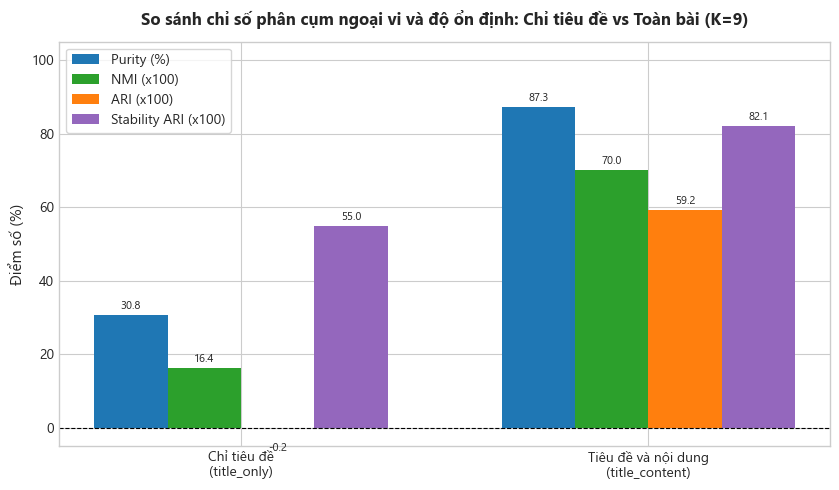

In [3]:
variants = metrics_df["variant_id"].tolist()
labels = [f"{vname}\n({vid})" for vid, vname in zip(variants, metrics_df["variant_name"])]
x = np.arange(len(variants))
width = 0.18

fig, ax = plt.subplots(figsize=(8.5, 5))
rects1 = ax.bar(x - 1.5 * width, metrics_df["purity"] * 100, width, label="Purity (%)", color="#1f77b4")
rects2 = ax.bar(x - 0.5 * width, metrics_df["nmi"] * 100, width, label="NMI (x100)", color="#2ca02c")
rects3 = ax.bar(x + 0.5 * width, metrics_df["ari"] * 100, width, label="ARI (x100)", color="#ff7f0e")
rects4 = ax.bar(x + 1.5 * width, metrics_df["stability_ari_mean"] * 100, width, label="Stability ARI (x100)", color="#9467bd")

ax.set_title("So sánh chỉ số phân cụm ngoại vi và độ ổn định: Chỉ tiêu đề vs Toàn bài (K=9)", fontsize=12, fontweight="bold", pad=12)
ax.set_ylabel("Điểm số (%)", fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=10)
ax.set_ylim(-5, 105)
ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.legend(loc="upper left", frameon=True)

for rects in [rects1, rects2, rects3, rects4]:
    for bar in rects:
        height = bar.get_height()
        va = "bottom" if height >= 0 else "top"
        y_pos = height if height >= 0 else height - 3
        ax.annotate(
            f"{height:.1f}",
            xy=(bar.get_x() + bar.get_width() / 2, y_pos),
            xytext=(0, 2 if height >= 0 else -2),
            textcoords="offset points",
            ha="center",
            va=va,
            fontsize=8,
        )

plt.tight_layout()
fig.savefig(FIGURES_DIR / "m03a_metrics_comparison.png", dpi=300)
plt.show()

### 3.2. Đánh đổi giữa kích thước từ vựng, độ thưa và thời gian tính toán

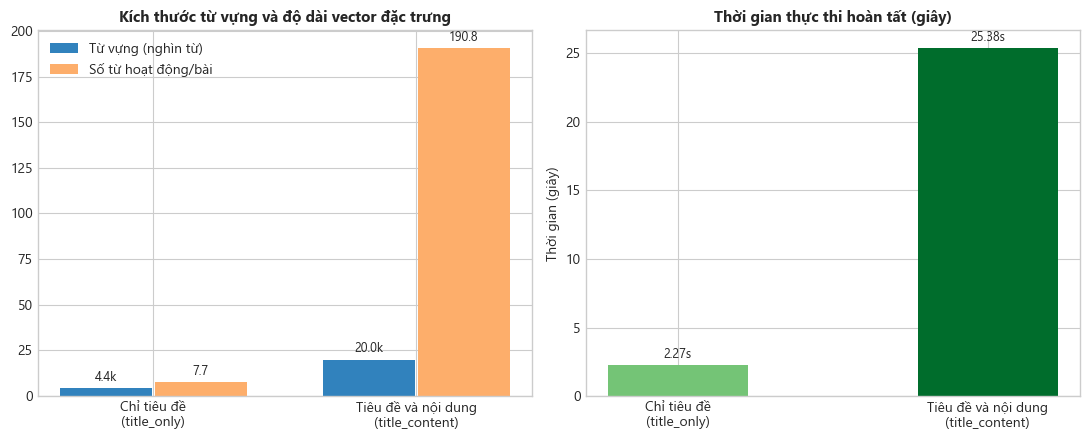

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

# Biểu đồ từ vựng và số từ trung bình hoạt động
bars1 = ax1.bar(x - 0.18, metrics_df["vocab_size"] / 1000, 0.35, label="Từ vựng (nghìn từ)", color="#3182bd")
bars2 = ax1.bar(x + 0.18, metrics_df["val_mean_active_terms"], 0.35, label="Số từ hoạt động/bài", color="#fdae6b")
ax1.set_title("Kích thước từ vựng và độ dài vector đặc trưng", fontsize=11, fontweight="bold")
ax1.set_xticks(x)
ax1.set_xticklabels(labels, fontsize=10)
ax1.legend(loc="upper left")

for bar in bars1:
    h = bar.get_height()
    ax1.annotate(f"{h:.1f}k", xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9)
for bar in bars2:
    h = bar.get_height()
    ax1.annotate(f"{h:.1f}", xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9)

# Biểu đồ thời gian thực thi tổng cộng
bars3 = ax2.bar(x, metrics_df["total_runtime_seconds"], 0.45, color=["#74c476", "#006d2c"])
ax2.set_title("Thời gian thực thi hoàn tất (giây)", fontsize=11, fontweight="bold")
ax2.set_ylabel("Thời gian (giây)", fontsize=10)
ax2.set_xticks(x)
ax2.set_xticklabels(labels, fontsize=10)

for bar in bars3:
    h = bar.get_height()
    ax2.annotate(f"{h:.2f}s", xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "m03a_vocab_and_runtime.png", dpi=300)
plt.show()

### 3.3. Phân tích chi tiết theo chuyên mục: Hiện tượng cụm nuốt chửng ở chỉ tiêu đề
Khi chỉ dùng tiêu đề, văn bản quá ngắn (trung bình ~10 từ) khiến các vector thưa thớt (99.83%), không đủ điểm tương đồng Euclid để tách cụm. Hậu quả là K-Means dồn hơn **70% bài báo** vào duy nhất Cụm 2, làm mất hoàn toàn khả năng phân tách chủ đề.

Cụm chiếm ưu thế            Độ thuần khiết cụm (%)  \
variant_id            title_content title_only          title_content   
category_gold                                                           
Giáo dục                          7          2                  97.67   
Giải trí                          0          2                  68.13   
Khoa học công nghệ                2          2                  92.11   
Kinh doanh                        6          2                  74.67   
Pháp luật                         5          2                  87.23   
Sức khỏe                          3          2                  98.74   
Thể thao                          4          2                 100.00   

                              Tỷ lệ bao phủ chuyên mục (%)             
variant_id         title_only                title_content title_only  
category_gold                                                          
Giáo dục                13.24                        80.77      83.33  
Giải trí                16.70                        96.07      92.13  
Khoa học công nghệ       7.03                        66.67      65.71  
Kinh doanh              17.92                        57.58      59.26  
Pháp luật               14.66                        92.66      81.36  
Sức khỏe                16.19                        84.86      85.95  
Thể thao                14.26                        59.39      47.78

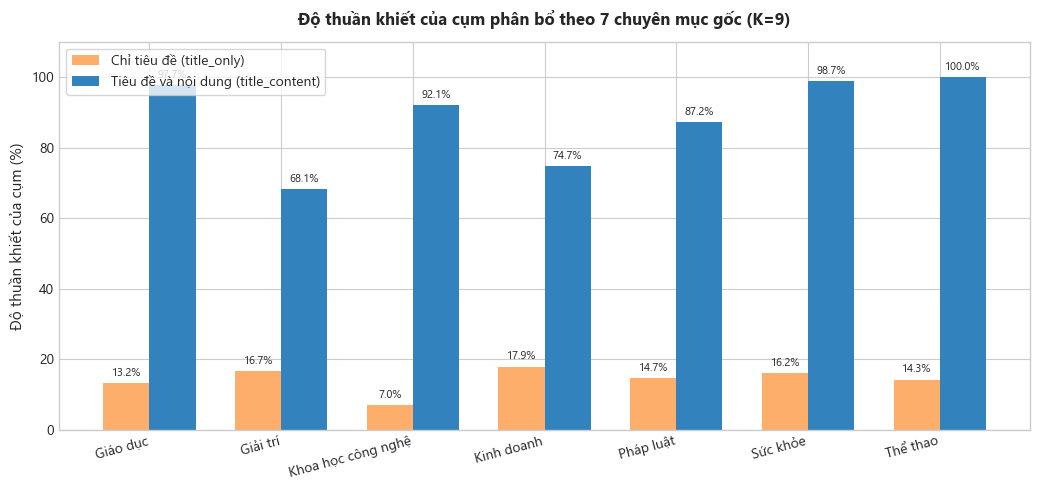

In [5]:
breakdown_path = RESULTS_DIR / "m03a_category_breakdown.csv"
breakdown_df = pd.read_csv(breakdown_path)

# Hiển thị bảng đối chiếu độ thuần khiết của cụm đại diện cho từng chuyên mục
pivot_purity = breakdown_df.pivot(index="category_gold", columns="variant_id", values="cluster_purity_pct")
pivot_cluster = breakdown_df.pivot(index="category_gold", columns="variant_id", values="dominant_cluster_id")
pivot_recall = breakdown_df.pivot(index="category_gold", columns="variant_id", values="category_recall_pct")

display(pd.concat({
    "Cụm chiếm ưu thế": pivot_cluster,
    "Độ thuần khiết cụm (%)": pivot_purity,
    "Tỷ lệ bao phủ chuyên mục (%)": pivot_recall,
}, axis=1))

# Biểu đồ so sánh độ thuần khiết cụm theo chuyên mục
cats = pivot_purity.index.tolist()
x_cat = np.arange(len(cats))
w_cat = 0.35

fig, ax = plt.subplots(figsize=(10.5, 5))
b_title = ax.bar(x_cat - w_cat / 2, pivot_purity["title_only"], w_cat, label="Chỉ tiêu đề (title_only)", color="#fdae6b")
b_full = ax.bar(x_cat + w_cat / 2, pivot_purity["title_content"], w_cat, label="Tiêu đề và nội dung (title_content)", color="#3182bd")

ax.set_title("Độ thuần khiết của cụm phân bổ theo 7 chuyên mục gốc (K=9)", fontsize=12, fontweight="bold", pad=12)
ax.set_ylabel("Độ thuần khiết của cụm (%)", fontsize=11)
ax.set_xticks(x_cat)
ax.set_xticklabels(cats, fontsize=10, rotation=15, ha="right")
ax.set_ylim(0, 110)
ax.legend(loc="upper left", frameon=True)

for bar in b_title:
    h = bar.get_height()
    ax.annotate(f"{h:.1f}%", xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8)
for bar in b_full:
    h = bar.get_height()
    ax.annotate(f"{h:.1f}%", xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "m03a_category_purity_comparison.png", dpi=300)
plt.show()

## 4. Kiểm tra độ nhạy với mốc đối chiếu $K=7$
Đối chiếu trên cả hai mốc $K=7$ (số chuyên mục gốc) và $K=9$ (mốc cấu hình chọn).

,variant_id,k,vocab_size,val_sparsity_pct,silhouette_score,davies_bouldin_index,purity,nmi,ari,stability_ari_mean
0,title_only,7,4437,99.8272,0.0046,6.7098,0.2955,0.1047,-0.0046,0.5983
1,title_only,9,4437,99.8272,0.0063,5.8107,0.3077,0.1637,-0.0016,0.5496
2,title_content,7,20000,99.0463,0.0205,6.6178,0.8210,0.6889,0.6239,0.8277
3,title_content,9,20000,99.0463,0.0190,6.1566,0.8728,0.7004,0.5925,0.8211


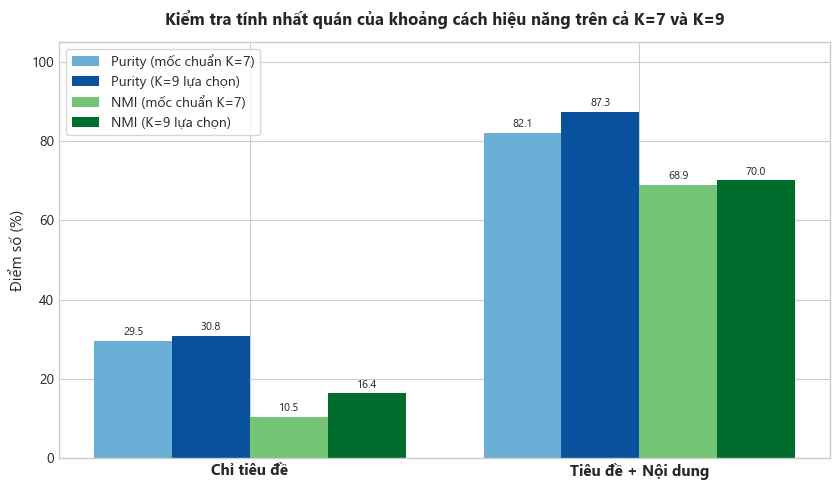

In [6]:
sens_path = RESULTS_DIR / "m03a_title_vs_content_k7_sensitivity.csv"
sens_df = pd.read_csv(sens_path)

display(sens_df[["variant_id", "k", "vocab_size", "val_sparsity_pct", "silhouette_score", "davies_bouldin_index", "purity", "nmi", "ari", "stability_ari_mean"]])

fig, ax = plt.subplots(figsize=(8.5, 5))
k7_data = sens_df[sens_df["k"] == 7].set_index("variant_id")
k9_data = sens_df[sens_df["k"] == 9].set_index("variant_id")

var_ids = ["title_only", "title_content"]
var_names = ["Chỉ tiêu đề", "Tiêu đề + Nội dung"]
k7_pur = [k7_data.loc[v, "purity"] * 100 for v in var_ids]
k9_pur = [k9_data.loc[v, "purity"] * 100 for v in var_ids]
k7_nmi = [k7_data.loc[v, "nmi"] * 100 for v in var_ids]
k9_nmi = [k9_data.loc[v, "nmi"] * 100 for v in var_ids]

x_s = np.arange(len(var_ids))
w_s = 0.2

r1 = ax.bar(x_s - 1.5 * w_s, k7_pur, w_s, label="Purity (mốc chuẩn K=7)", color="#6baed6")
r2 = ax.bar(x_s - 0.5 * w_s, k9_pur, w_s, label="Purity (K=9 lựa chọn)", color="#08519c")
r3 = ax.bar(x_s + 0.5 * w_s, k7_nmi, w_s, label="NMI (mốc chuẩn K=7)", color="#74c476")
r4 = ax.bar(x_s + 1.5 * w_s, k9_nmi, w_s, label="NMI (K=9 lựa chọn)", color="#006d2c")

ax.set_title("Kiểm tra tính nhất quán của khoảng cách hiệu năng trên cả K=7 và K=9", fontsize=12, fontweight="bold", pad=12)
ax.set_ylabel("Điểm số (%)", fontsize=11)
ax.set_xticks(x_s)
ax.set_xticklabels(var_names, fontsize=11, fontweight="bold")
ax.set_ylim(0, 105)
ax.legend(loc="upper left", frameon=True)

for rects in [r1, r2, r3, r4]:
    for bar in rects:
        h = bar.get_height()
        ax.annotate(f"{h:.1f}", xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 2), textcoords="offset points", ha="center", va="bottom", fontsize=8)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "m03a_k7_vs_k9_sensitivity.png", dpi=300)
plt.show()

## 5. Dẫn chứng định tính từng cụm: So sánh từ khóa và bài viết tiêu biểu ($K=9$)

In [7]:
qual_path = RESULTS_DIR / "m03a_qualitative_cluster_examples.csv"
qual_df = pd.read_csv(qual_path)

title_sample = qual_df[qual_df["variant_id"] == "title_only"][["cluster_id", "size_val", "dominant_gold_category", "top10_keywords", "nearest_article_title"]]
content_sample = qual_df[qual_df["variant_id"] == "title_content"][["cluster_id", "size_val", "dominant_gold_category", "top10_keywords", "nearest_article_title"]]

print("CHỈ TIÊU ĐỀ (Cụm 2 bị phình to 982 bài, từ khóa nghèo nàn)")
display(title_sample.head(5))

print("\nTIÊU ĐỀ VÀ NỘI DUNG (Cụm cân đối, từ ghép chuyên ngành rõ nét)")
display(content_sample.head(5))

CHỈ TIÊU ĐỀ (Cụm 2 bị phình to 982 bài, từ khóa nghèo nàn)


,cluster_id,size_val,dominant_gold_category,top10_keywords,nearest_article_title
0,0,44,Kinh doanh,"giảm, tăng, lãi_suất, ngân_hàng, fed, mạnh, ch...",Fed tăng lãi suất lần đầu tiên sau 3 năm
1,1,69,Thể thao,"việt_nam, tuyển, lan, thái, hlv, u20, thắng, h...",HLV Thái Lan có thể bị sa thải nếu lại thua tu...
2,2,982,Kinh doanh,"không, trường, tuổi, tp, hcm, vụ, mới, 2026, h...",Học sinh TP.HCM học đờn ca tài tử: Không lấy đ...
3,3,13,Thể thao,"asean, cup, fifa, 2026, tuyển, việt, lan, nam,...",Việt Nam có bản quyền FIFA ASEAN Cup 2026
4,4,60,Thể thao,"asiad, 20, 2026, nam, u23, việt_nam, việt, lịc...",Lịch thi đấu của U23 Việt Nam tại ASIAD 2026



TIÊU ĐỀ VÀ NỘI DUNG (Cụm cân đối, từ ghép chuyên ngành rõ nét)


,cluster_id,size_val,dominant_gold_category,top10_keywords,nearest_article_title
9,0,251,Giải trí,"cô, phim, anh, khán_giả, không, diễn_viên, tôi...",Mỹ Anh: Không đợi thành công trong nước rồi mớ...
10,1,98,Thể thao,"asiad, nữ, u23, nam, giành, thi_đấu, việt_nam,...",Xác định 8 đội vào tứ kết bóng đá nữ Asiad 20
11,2,76,Khoa học công nghệ,"iphone, apple, pro, máy, dùng, màn_hình, max, ...","Toàn cảnh thông tin hot nhất về iPhone 18 Pro,..."
12,3,159,Sức khỏe,"bác_sĩ, bệnh, điều_trị, bệnh_viện, người_bệnh,...",5 điều cần biết để giữ thận khỏe
13,4,174,Thể thao,"trận, đội, bóng, cầu_thủ, hlv, cup, thắng, sân...",HLV tuyển Philippines: 'Chúng tôi không đáng t...
